# 04 - Feature Engineering ve Feature Selection

**Sorumlu:** Melike Türkdal

**Ödevdeki karşılığı:** 2. Veri Ön İşleme (Feature Engineering, Feature Selection/Importance)

In [3]:
# KURULUM: bu hucreyi her oturumun basinda bir kez calistir.
# Repoyu Colab'e indirir; boylece src/ortak.py kullanilabilir.
import os
REPO_URL = "https://github.com/zeyneppbaran/ml-proje.git"  # TODO: kendi repo adresiniz
if not os.path.exists("/content/ml-proje"):
    !git clone {REPO_URL} /content/ml-proje
else:
    !git -C /content/ml-proje pull
%cd /content/ml-proje

Cloning into '/content/ml-proje'...
remote: Enumerating objects: 229, done.
remote: Counting objects: 100% (229/229), done.
remote: Compressing objects: 100% (203/203), done.
remote: Total 229 (delta 122), reused 70 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (229/229), 4.23 MiB | 11.25 MiB/s, done.
Resolving deltas: 100% (122/122), done.
/content/ml-proje


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.ortak import veri_yukle, veriyi_bol, on_isleyici, ortak_cv, RANDOM_STATE

df = veri_yukle()
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,daha_once_aranmis,pdays_kayitli
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0


## D4. Yeni özellikler

### D4.1 Ortak Pipeline'da Üretilen Özelliklerin Analizi

`veri_yukle()` içinde (Kişi 3) iki özellik türetilmiştir: `daha_once_aranmis = (previous > 0)` ve `pdays_kayitli = (pdays != 999)`. Bu bölümde üç soru ölçülerek cevaplanır:
1. `daha_once_aranmis` yeni bilgi taşıyor mu?
2. `pdays_kayitli` neden gerekli?
3. İkisi modelin performansına katkı sağlıyor mu? (ablasyon testi)

In [4]:
# daha_once_aranmis, poutcome'un 'nonexistent' olmamasıyla birebir aynı mı?
esdeger = (df["daha_once_aranmis"] == (df["poutcome"] != "nonexistent").astype(int)).all()
print("daha_once_aranmis == (poutcome != 'nonexistent') tüm satırlarda:", esdeger)
display(pd.crosstab(df["daha_once_aranmis"], df["poutcome"]))

daha_once_aranmis == (poutcome != 'nonexistent') tüm satırlarda: True


poutcome,failure,nonexistent,success
daha_once_aranmis,,,
0,0,35551,0
1,4252,0,1373


In [5]:
# pdays=999 -> NaN -> medyan ile doldurulunca ne oluyor? (sadece train üzerinde)
X_train, X_val, X_test, y_train, y_val, y_test = veriyi_bol(df)
medyan = X_train["pdays"].median()
tr = X_train.assign(y=y_train.values)

kayitsiz = tr[tr["pdays"].isna()]        # hiç kaydı olmayanlar -> imputer bunlara medyanı yazacak
gercek   = tr[tr["pdays"] == medyan]     # gerçekten 'medyan' gün önce aranmış olanlar

print(f"Imputer'ın dolduracağı değer (train medyanı): {medyan:.0f} gün")
print(f"Kaydı olmayan müşteri     : {len(kayitsiz):>6} kişi | abonelik oranı %{kayitsiz['y'].mean()*100:.1f}")
print(f"Gerçekten {medyan:.0f} gün önce aranan: {len(gercek):>6} kişi | abonelik oranı %{gercek['y'].mean()*100:.1f}")

# pdays_kayitli'nin poutcome'a eklediği tek yeni bilgi: failure grubunun ikiye ayrılması
display(df[df["poutcome"] == "failure"].groupby("pdays_kayitli")["y"]
        .agg(Kayit="count", Abonelik_Orani="mean").round(3))

Imputer'ın dolduracağı değer (train medyanı): 6 gün
Kaydı olmayan müşteri     :  27745 kişi | abonelik oranı %9.2
Gerçekten 6 gün önce aranan:    290 kişi | abonelik oranı %71.7


,Kayit,Abonelik_Orani
pdays_kayitli,,
0,4110,0.129
1,142,0.514


**1. Bu iki sütun neden oluşturuldu?**

Veri setindeki pdays sütunu, müşterinin son aranmasından bu yana kaç gün geçtiğini gösterir. Bu bilgi yoksa sütuna 999 yazılmıştır. Ama 999 değeri iki farklı müşteri tipini aynı kalıba sokuyor:

* daha önce **hiç aranmamış** müşteriler,
* daha önce **aranmış ama gün sayısı kaydedilmemiş** müşteriler.

Bu iki grup birbirinden farklıdır, fakat model pdays'e bakarak onları ayıramaz. Ayrıca 999 gerçek bir gün sayısı değildir. Model onu "çok uzun zaman önce arandı" diye yanlış yorumlayabilir.

Bu sorunu çözmek için iki yardımcı sütun türetildi:

* `daha_once_aranmis`: Müşteri daha önce hiç arandı mı?
* `pdays_kayitli`: Gün sayısı gerçekten kayıtlı mı? Bu sütun bir **eksik değer göstergesidir (missing indicator)**. 999 değerleri boş bırakılıp ortanca değerle doldurulduktan sonra, hangi değerlerin gerçek hangilerinin doldurulmuş olduğunu bu sütun hatırlar.

İkisi birlikte müşterileri üç anlamlı gruba ayırır: **hiç aranmamış, aranmış ama kaydı yok, aranmış ve kaydı var.**


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

df_ham = df.copy()
df_ham["pdays"] = df_ham["pdays"].fillna(999)   # 999 kodunu geri koy (ham hali)

def pre_cikar(cikar):
    p = on_isleyici()
    p.transformers = [(a, t, [c for c in cols if c not in cikar]) for a, t, cols in p.transformers]
    return p

modeller = {
    "LR": lambda: LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RF": lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                         random_state=RANDOM_STATE, n_jobs=-1),
}
senaryolar = [
    ("A: Ham (999 kodu, türetilmiş yok)", df_ham, ["daha_once_aranmis", "pdays_kayitli"]),
    ("B: Mevcut ortak pipeline",           df,     []),
    ("C: B - daha_once_aranmis",           df,     ["daha_once_aranmis"]),
    ("D: B - pdays_kayitli",               df,     ["pdays_kayitli"]),
    ("E: B - ikisi",                       df,     ["daha_once_aranmis", "pdays_kayitli"]),
]
satirlar = []
for ad, d, cikar in senaryolar:
    Xtr, _, _, ytr, _, _ = veriyi_bol(d)
    satir = {"Senaryo": ad}
    for m, f in modeller.items():
        s = cross_val_score(Pipeline([("on_isleme", pre_cikar(cikar)), ("model", f())]),
                            Xtr, ytr, cv=ortak_cv(), scoring="roc_auc", n_jobs=-1)
        satir[f"{m} ROC-AUC"] = f"{s.mean():.4f} ± {s.std():.4f}"
    satirlar.append(satir)
display(pd.DataFrame(satirlar))

,Senaryo,LR ROC-AUC,RF ROC-AUC
0,"A: Ham (999 kodu, türetilmiş yok)",0.7888 ± 0.0106,0.7923 ± 0.0098
1,B: Mevcut ortak pipeline,0.7888 ± 0.0106,0.7926 ± 0.0104
2,C: B - daha_once_aranmis,0.7888 ± 0.0107,0.7925 ± 0.0105
3,D: B - pdays_kayitli,0.7883 ± 0.0109,0.7921 ± 0.0101
4,E: B - ikisi,0.7883 ± 0.0109,0.7919 ± 0.0091


**2. Bilgi taşıdıkları hâlde neden skora yansımadı?**

Çünkü model aynı bilgiyi başka bir yerden zaten alıyor. Önceki kampanyanın sonucunu tutan poutcome sütunu üç değer alır: "önceki kampanya yok", "başarısız", "başarılı". "Önceki kampanya yok" değeri, "hiç aranmamış" demekle aynı şeydir. Yani yeni sütunların yaptığı ayrımın büyük kısmını poutcome zaten yapıyor. Yeni sütunların eklediği tek gerçek bilgi çok küçük bir müşteri grubuna ait, bu yüzden genel skorda fark görünmüyor.

**Not: Küçük müşteri grubu (142 kişi)**  
`daha_once_aranmis` ve `pdays_kayitli` sütunlarının `poutcome`'a eklediği tek yeni bilgi, önceki kampanyası başarısız olan müşterileri ikiye ayırmaktır:
- Gün sayısı kayıtlı olmayanlar: kalabalık bir grup, vadeli mevduat açma oranı düşük.
- Gün sayısı kayıtlı olanlar: yalnızca 142 müşteri (verinin yaklaşık binde 3'ü), vadeli mevduat açma oranı yaklaşık 4 kat daha yüksek.

Bu ayrımı yalnızca `pdays_kayitli` yapabilir. Bilgi gerçek ama grup çok küçük olduğu için tüm veri üzerinden ölçülen ROC-AUC skorunda fark yaratmıyor.

**Sonuç:** Sütunların tasarım mantığı doğru. Veri setindeki gerçek bir sorunu (999 kodunun iki farklı grubu karıştırmasını) çözüyorlar. Performansa katkıları küçük, çünkü aynı bilgi büyük ölçüde zaten vardı. Yine de pipeline'da tutuldular, çünkü işlevleri verinin doğru temsil edilmesi. Özellikle pdays_kayitli olmadan, hiç aranmamış müşteriler modele "birkaç gün önce arandı" gibi görünürdü.

### D4.2 Yeni Özellik Adayları

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

def ozellik_ekle(d):
    """Satır bazlı, veriden öğrenmeyen dönüşümler (veri sızıntısı yok)."""
    d = d.copy()
    d["yas_grubu"] = pd.cut(d["age"], bins=[0, 25, 35, 45, 55, 60, 120],
                            labels=["<=25", "26-35", "36-45", "46-55", "56-60", ">60"]).astype(str)
    d["calismiyor"] = d["job"].isin(["student", "retired", "unemployed"]).astype(int)
    d["kampanya_log"] = np.log1p(d["campaign"])
    d["toplam_temas"] = d["campaign"] + d["previous"]
    d["ilk_arama"] = (d["campaign"] == 1).astype(int)
    d["kredi_sayisi"] = (d["housing"] == "yes").astype(int) + (d["loan"] == "yes").astype(int)
    d["dusuk_faiz"] = (d["euribor3m"] < 2).astype(int)
    d["cep_x_dusuk_faiz"] = ((d["contact"] == "cellular") & (d["euribor3m"] < 2)).astype(int)
    return d

df_fe = ozellik_ekle(df)

# Adım 1: Tek başına sinyal (gruplara göre vadeli mevduat açma oranı)
for c in ["yas_grubu", "calismiyor", "ilk_arama", "dusuk_faiz", "cep_x_dusuk_faiz"]:
    display(df_fe.groupby(c)["y"].agg(Kayit="count", Acma_Orani="mean").round(3).T)

yas_grubu,26-35,36-45,46-55,56-60,<=25,>60
Kayit,14844.000,12839.000,8247.000,2672.000,1665.00,909.000
Acma_Orani,0.117,0.085,0.087,0.122,0.21,0.455


calismiyor,0,1
Kayit,37569.000,3607.000
Acma_Orani,0.101,0.236


ilk_arama,0,1
Kayit,23542.000,17634.00
Acma_Orani,0.099,0.13


dusuk_faiz,0,1
Kayit,27682.000,13494.000
Acma_Orani,0.048,0.245


cep_x_dusuk_faiz,0,1
Kayit,29011.000,12165.000
Acma_Orani,0.055,0.251


In [10]:
# Adım 2: Modele katkı (eşleştirilmiş 5 katlı CV, sadece train) — yaklaşık 1 dakika sürer
Xtr_fe, _, _, ytr_fe, _, _ = veriyi_bol(df_fe)

adaylar = {"yas_grubu": "kat", "calismiyor": "num", "kampanya_log": "num", "toplam_temas": "num",
           "ilk_arama": "num", "kredi_sayisi": "num", "dusuk_faiz": "num", "cep_x_dusuk_faiz": "num"}

def on_isleme_ekle(ekle):
    p = on_isleyici()
    kat = [c for c in ekle if adaylar[c] == "kat"]
    num = [c for c in ekle if adaylar[c] == "num"]
    if kat: p.transformers.append(("yeni_kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kat))
    if num: p.transformers.append(("yeni_num", "passthrough", num))
    return p

modeller = {
    "LR":  lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
    "HGB": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=RANDOM_STATE),
}
def cv_skor(ekle, m):
    p = Pipeline([("on_isleme", on_isleme_ekle(ekle)), ("model", modeller[m]())])
    return cross_val_score(p, Xtr_fe, ytr_fe, cv=ortak_cv(), scoring="roc_auc", n_jobs=-1)

temel = {m: cv_skor([], m) for m in modeller}
print({m: round(s.mean(), 4) for m, s in temel.items()}, "<- ortak pipeline (temel)")

satirlar = []
for c in list(adaylar) + ["HEPSİ"]:
    ekle = list(adaylar) if c == "HEPSİ" else [c]
    satir = {"Özellik": c}
    for m in modeller:
        fark = cv_skor(ekle, m) - temel[m]              # aynı katlarda fark
        satir[f"{m} fark"] = round(fark.mean(), 4)
        satir[f"{m} oynama"] = round(fark.std(), 4)
        satir[f"{m} artan kat"] = f"{(fark > 0).sum()}/5"
        satir[f"{m} karar"] = "EKLE" if (fark.mean() > fark.std() and (fark > 0).sum() >= 4) else "-"
    satirlar.append(satir)
sonuc = pd.DataFrame(satirlar)
display(sonuc)

{'LR': np.float64(0.7888), 'HGB': np.float64(0.7993)} <- ortak pipeline (temel)


,Özellik,LR fark,LR oynama,LR artan kat,LR karar,HGB fark,HGB oynama,HGB artan kat,HGB karar
0,yas_grubu,-0.0002,0.0014,3/5,-,-0.0006,0.0012,2/5,-
1,calismiyor,-0.0000,0.0001,1/5,-,-0.0009,0.0019,1/5,-
2,kampanya_log,0.0008,0.0009,4/5,-,0.0000,0.0000,0/5,-
3,toplam_temas,0.0000,0.0000,3/5,-,-0.0016,0.0014,0/5,-
4,ilk_arama,0.0007,0.0008,3/5,-,0.0000,0.0000,0/5,-
5,kredi_sayisi,-0.0000,0.0001,1/5,-,-0.0002,0.0013,2/5,-
6,dusuk_faiz,-0.0001,0.0001,1/5,-,0.0000,0.0000,0/5,-
7,cep_x_dusuk_faiz,0.0000,0.0001,3/5,-,-0.0021,0.0019,0/5,-
8,HEPSİ,0.0005,0.0022,4/5,-,-0.0013,0.0006,0/5,-


### Yorum: Yeni özelliklerin modele katkısı

#### 1. Amaç
Bu analizde, mevcut sütunlardan türetilen sekiz yeni özelliğin modelin tahmin başarısını gerçekten artırıp artırmadığı ölçülmüştür. Yeni bir özelliğin hedefle ilişkili görünmesi (tek başına sinyal taşıması), onun modele katkı sağlayacağı anlamına gelmez. Model aynı bilgiyi başka sütunlardan zaten alıyor olabilir. Bu yüzden her özellik, modele eklendiğinde skoru değiştirip değiştirmediğine bakılarak değerlendirilmiştir.

#### 2. Yöntem
- **Karşılaştırma noktası (temel):** Hiçbir yeni özellik eklenmeden, ortak pipeline ile elde edilen 5 katlı çapraz doğrulama ROC-AUC skoru (Lojistik Regresyon: 0.7888, HistGradientBoosting: 0.7993).
- **Deneme:** Her özellik modele tek tek eklenmiş ve aynı test tekrarlanmıştır. Son satırda ("HEPSİ") sekiz özellik birlikte eklenmiştir.
- **Eşleştirilmiş karşılaştırma:** Temel model ve özellik eklenmiş model, aynı 5 eğitim/doğrulama bölmesinde (kat) çalıştırılmıştır. Böylece her katta iki skor doğrudan karşılaştırılabilmiş ve farkın veri bölünmesinden değil, eklenen özellikten kaynaklandığı güvence altına alınmıştır.
- **İki farklı model:** Lojistik Regresyon (LR, doğrusal) ve HistGradientBoosting (HGB, ağaç tabanlı) kullanılmıştır. Çünkü bir dönüşüm doğrusal modele yarayıp ağaç modeline yaramayabilir.
- **Veri sızıntısı önlemi:** Tüm ölçümler yalnızca eğitim verisi üzerinde yapılmıştır. Doğrulama ve test setleri bu analizde kullanılmamıştır. Yeni özellikler satır bazlı kurallarla üretildiği için veriden istatistik öğrenmezler.
- **Karar kuralı (test öncesinde belirlenmiştir):** Bir özellik ancak (1) ortalama skor artışı katlar arasındaki dalgalanmadan büyükse ve (2) 5 katın en az 4'ünde skor artıyorsa eklenir. Amaç, şans eseri oluşan küçük iyileşmeleri gerçek katkıdan ayırmaktır.

#### 3. Tablonun okunması
- **fark:** Özellik eklendiğinde ROC-AUC'nin temel skora göre ortalama değişimi. Pozitif değer iyileşme, negatif değer kötüleşme, 0 değişiklik yok anlamına gelir.
- **oynama:** Bu farkın 5 kat arasındaki standart sapması. Fark oynamadan küçükse, gözlenen değişim şans eseri olabilir.
- **artan kat:** 5 katın kaçında skorun arttığı. 5/5 tutarlı bir iyileşme, 0/5 hiç iyileşme olmadığını gösterir.
- **karar:** Karar kuralını geçen özellikler "EKLE", geçemeyenler "-" ile gösterilmiştir.

#### 4. Bulgular
- **Hiçbir özellik karar kuralını geçememiştir.** Tüm farklar, katlar arası doğal dalgalanma düzeyinde kalmıştır.
- **Lojistik Regresyon:** `kampanya_log` (5 katın 4'ünde artış) ve `ilk_arama` (5 katın 3'ünde artış) küçük ama çoğunlukla aynı yönde bir iyileşme göstermiştir. Bu, `campaign` sütununun çarpık dağılımını düzeltmenin doğrusal modele yarayacağı hipotezini destekler. Ancak artış, katlar arası dalgalanmayı aşmadığı için anlamlı kabul edilmemiştir. Diğer özelliklerde fark yaklaşık sıfırdır.
- **HistGradientBoosting:** `kampanya_log`, `ilk_arama` ve `dusuk_faiz` özelliklerinde fark tam olarak sıfırdır. Yani ağaç modeli bu özellikler eklense de eklenmese de birebir aynı sonucu üretmiştir. `toplam_temas`, `cep_x_dusuk_faiz` ve `calismiyor` gibi özellikler ise skoru hafifçe düşürmüştür. Sekiz özellik birlikte eklendiğinde 5 katın hiçbirinde iyileşme görülmemiştir.

#### 5. Bulguların açıklaması
1. **Yeni özellikler yeni bilgi getirmez.** Hepsi modelin zaten gördüğü sütunlardan türetilmiştir (`dusuk_faiz` euribor'dan, `yas_grubu` yaştan, `calismiyor` meslekten). Model aynı bilgiye orijinal sütunlar üzerinden zaten erişebilmektedir.
2. **Ağaç modelleri bu dönüşümleri kendileri yapar.** Karar ağaçları veriyi "euribor 2'den küçük mü?", "yaş 60'tan büyük mü?" gibi eşik sorularıyla böler. Log dönüşümü gibi sıralamayı değiştirmeyen işlemler bu soruların cevabını değiştirmediği için ağaç modeline hiçbir etki yapmaz. Sıfır farkların nedeni budur.
3. **Doğrusal model kısmen faydalanabilir.** Lojistik Regresyon her sütunla doğrusal bir ilişki kurar ve çarpık dağılımları ya da eşik etkilerini kendisi modelleyemez. Bu yüzden küçük iyileşmeler yalnızca LR tarafında görülmüştür. Ancak bu iyileşmeler de anlamlı düzeye ulaşmamıştır.
4. **Gereksiz özellikler modeli bozabilir.** Yeni bilgi taşımayan sütunlar, ağaç modelinin yanlış bölmeler yapma ihtimalini artırır. Tüm özellikler birlikte eklendiğinde HGB skorunun her katta düşmesi bunu göstermektedir.

#### 6. Karar
Yeni özelliklerin hiçbiri ortak pipeline'a eklenmemiştir. Bu sonuç, mevcut sütunlarla ulaşılabilecek bilgi sınırına gelindiğini göstermektedir. Modelin başarısını artırmak için mevcut sütunları yeniden düzenlemek yeterli değildir. Müşterinin geliri ya da bankayla geçmiş ilişkisi gibi yeni bir bilgi kaynağı gerekir, ancak bu veri setinde böyle bilgiler bulunmamaktadır. Görüşme süresi (`duration`) ise arama bitmeden bilinemeyeceği ve veri sızıntısı yaratacağı için modelden çıkarılmıştır.

## D5 Feature Selection

**Amaç:** Vadeli mevduat açma kararını tahmin ederken hangileri gerçekten işe yarıyor, hangileri neredeyse hiç katkı sağlamıyor.

### D5a. yöntemi 1 : Mutual Information

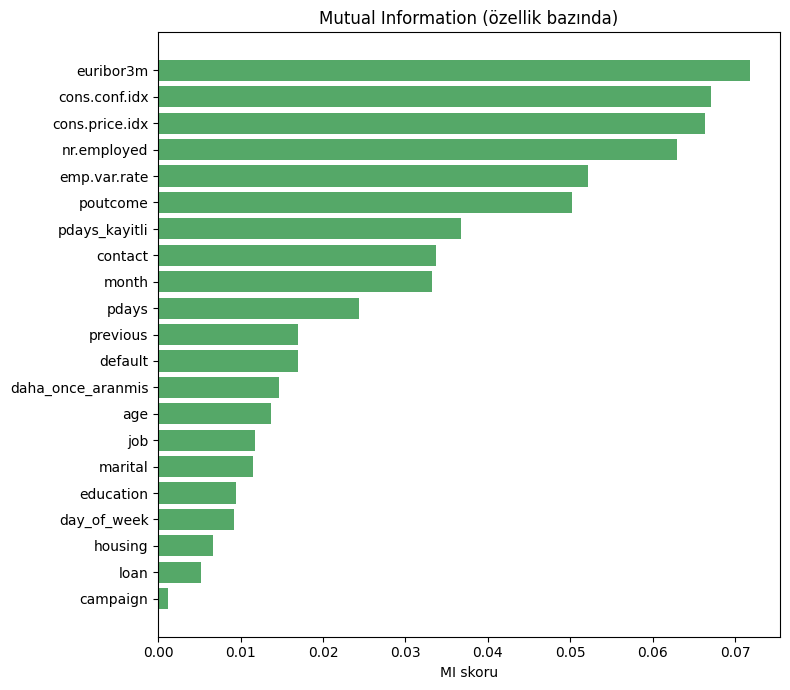

,0
euribor3m,0.0719
cons.conf.idx,0.0671
cons.price.idx,0.0664
nr.employed,0.0630
emp.var.rate,0.0522
poutcome,0.0502
pdays_kayitli,0.0367
contact,0.0337
month,0.0332
pdays,0.0244


In [5]:
from sklearn.feature_selection import mutual_info_classif

# 1) Veriyi böl, ön işleyiciyi SADECE train'e fit et (veri sızıntısı yok)
X_train, X_val, X_test, y_train, y_val, y_test = veriyi_bol(df)
pre = on_isleyici()
Xtr = pre.fit_transform(X_train)
adlar = [a.split("__", 1)[1] for a in pre.get_feature_names_out()]

# 2) Her işlenmiş sütun için MI skorunu hesapla
mi = pd.Series(mutual_info_classif(Xtr, y_train, random_state=RANDOM_STATE), index=adlar)

# 3) One-hot sütunlarını orijinal özelliğe topla (month_may, month_jun ... -> month)
sutunlar = sorted(X_train.columns, key=len, reverse=True)  # 'pdays_kayitli', 'pdays'ten önce denensin
def orijinal(ad):
    for c in sutunlar:
        if ad == c or ad.startswith(c + "_"):
            return c
mi_ozellik = mi.groupby(mi.index.map(orijinal)).sum().sort_values(ascending=False)

# 4) Grafik
plt.figure(figsize=(8, 7))
plt.barh(mi_ozellik.index, mi_ozellik.values, color="#55A868")
plt.gca().invert_yaxis()
plt.title("Mutual Information (özellik bazında)"); plt.xlabel("MI skoru")
plt.tight_layout(); plt.savefig("figures/d5a_mutual_information.png", dpi=300, bbox_inches="tight"); plt.show()
mi_ozellik.round(4)

**Yorum:**
Mutual Information (MI), bir özelliği bilmenin hedef değişken (vadeli mevduat açma) hakkındaki belirsizliği ne kadar azalttığını ölçer. 0 değeri özelliğin hiç bilgi taşımadığını gösterir. Değer büyüdükçe özellik daha bilgilendiricidir. Hedef değişkenin toplam belirsizliği (entropisi) yaklaşık 0.35'tir. Buna göre en güçlü özellik olan `euribor3m` (0.072), bu belirsizliğin yaklaşık beşte birini tek başına açıklamaktadır.

Özellikler dört gruba ayrılarak incelenmiştir:

1. **Ekonomik dönem göstergeleri (en yüksek MI):** `euribor3m`, `cons.conf.idx`, `cons.price.idx`, `nr.employed` ve `emp.var.rate` ilk beş sırayı almıştır. Bu göstergeler müşteriye değil, aramanın yapıldığı döneme aittir. Faizlerin ve istihdamın düşük olduğu dönemlerde vadeli mevduat açma oranı belirgin şekilde artmaktadır. Kararı en çok etkileyen faktör dönemin ekonomik koşullarıdır.

2. **Önceki kampanya geçmişi (yüksek–orta MI):** `poutcome`, `pdays_kayitli`, `pdays`, `previous` ve `daha_once_aranmis`. Daha önce bankayla iletişim kurmuş, özellikle önceki kampanyada olumlu sonuç vermiş müşteriler belirgin şekilde ayrışmaktadır. `pdays_kayitli`'nin `pdays`'ten daha yüksek skor alması, "son aramadan bu yana gün sayısı kayıtlı mı?" bilgisinin gün sayısının kendisinden daha değerli olduğunu gösterir. Bu, D4.1'de bu sütunun eksik değer göstergesi olarak tutulması kararını desteklemektedir. `daha_once_aranmis`'in `poutcome`'dan düşük çıkması beklenen bir sonuçtur, çünkü aynı bilginin daha az ayrıntılı hâlidir.

3. **Aramanın zamanı ve kanalı (orta MI):** `contact` (cep telefonu / sabit hat) ve `month` orta düzeyde bilgi taşırken `day_of_week` düşük kalmıştır. Hangi ay ve hangi kanalla arandığı önemlidir, ancak haftanın hangi günü arandığı belirleyici değildir.

4. **Müşterinin kişisel bilgileri (düşük MI):** `age`, `job`, `marital`, `education`, `default`, `housing` ve `loan` alt sıralardadır. Müşterinin yaşı, mesleği, medeni durumu ve kredi durumu tek başına vadeli mevduat kararı hakkında az bilgi vermektedir.

5. **`campaign` (en düşük MI):** Bu kampanyada kaç kez arandığı bilgisi tek başına neredeyse hiç bilgi taşımamaktadır.

**Sınırlamalar:**
- MI her özelliğe tek başına bakar. Ekonomik göstergeler birbiriyle güçlü şekilde ilişkili olduğundan (D5c'de gösterilmiştir), beşinin birden yüksek skor alması beşinin de modele ayrı ayrı katkı sağlayacağı anlamına gelmez.
- Kategorik özelliklerin skoru, one-hot kodlanmış alt sütunların skorları toplanarak elde edilmiştir. Bu yaklaşık bir değerdir ve sıralama için yeterlidir.
- MI, bir özelliğin diğer özelliklerle birlikte sağladığı katkıyı (etkileşimleri) göremez. Bu yüzden sonuçlar D5b'deki model tabanlı yöntemle karşılaştırılmıştır.

In [10]:
# Hedef değişkenin entropisi (toplam belirsizlik) – MI ile aynı birim (nat)
p = y_train.mean()
H = -(p * np.log(p) + (1 - p) * np.log(1 - p))
print(f"Vadeli mevduat açma oranı (p): {p:.4f}")
print(f"Hedefin entropisi H(y)        : {H:.3f} nat (dengeli veride en fazla ln2 = {np.log(2):.3f})")
print(f"euribor3m'in açıkladığı pay   : %{mi_ozellik['euribor3m'] / H * 100:.1f}")

Vadeli mevduat açma oranı (p): 0.1127
Hedefin entropisi H(y)        : 0.352 nat (dengeli veride en fazla ln2 = 0.693)
euribor3m'in açıkladığı pay   : %20.4


## D5b. Feature selection yöntemi 2

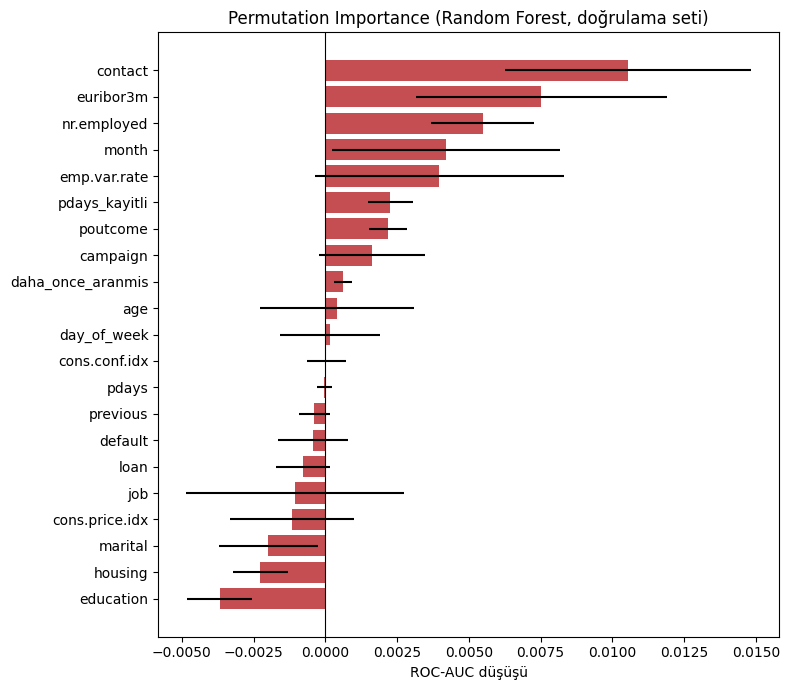

,0
contact,0.0105
euribor3m,0.0075
nr.employed,0.0055
month,0.0042
emp.var.rate,0.0040
pdays_kayitli,0.0023
poutcome,0.0022
campaign,0.0016
daha_once_aranmis,0.0006
age,0.0004


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# 1) Modeli SADECE train'de eğit
rf = Pipeline([("on_isleme", on_isleyici()),
               ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                class_weight="balanced",
                                                random_state=RANDOM_STATE, n_jobs=-1))])
rf.fit(X_train, y_train)

# 2) Doğrulama setinde her sütunu 5 kez karıştır, ROC-AUC düşüşünü ölç
pi = permutation_importance(rf, X_val, y_val, scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pi_ozellik = pd.Series(pi.importances_mean, index=X_val.columns).sort_values(ascending=False)
pi_std = pd.Series(pi.importances_std, index=X_val.columns)[pi_ozellik.index]

# 3) Grafik (hata çubukları = 5 tekrar arasındaki dalgalanma)
plt.figure(figsize=(8, 7))
plt.barh(pi_ozellik.index, pi_ozellik.values, xerr=pi_std, color="#C44E52")
plt.gca().invert_yaxis(); plt.axvline(0, color="k", lw=0.8)
plt.title("Permutation Importance (Random Forest, doğrulama seti)")
plt.xlabel("ROC-AUC düşüşü")
plt.tight_layout(); plt.savefig("figures/d5b_permutation_importance.png", dpi=300, bbox_inches="tight"); plt.show()
pi_ozellik.round(4)

**Yorum:**
Permutation importance, eğitilmiş bir modelde bir özelliğin değerleri rastgele karıştırıldığında modelin performansının (ROC-AUC) ne kadar düştüğünü ölçer. Model eğitim verisinde eğitilmiş, önem değerleri ise modelin görmediği doğrulama setinde hesaplanmıştır. Her özellik 5 kez karıştırılmış, çubuklar ortalama düşüşü, siyah çizgiler ise 5 tekrar arasındaki dalgalanmayı (standart sapma) göstermektedir. Dalgalanma çizgisi sıfırı kesmeyen özelliklerin önemi güvenilir kabul edilmiştir. Negatif değerler, özellik karıştırıldığında modelin hafifçe iyileştiğini, yani modelin o özellikten anlamlı bir şey öğrenmediğini gösterir.

**Bulgular:**
1. **Güvenilir şekilde önemli özellikler:** `contact`, `euribor3m`, `nr.employed`, `pdays_kayitli` ve `poutcome`. Model en çok arama kanalına, ekonomik döneme ve müşterinin önceki kampanya geçmişine dayanmaktadır. `daha_once_aranmis`'in katkısı küçük ama tutarlıdır.
2. **Önemli ama dalgalı özellikler:** `month`, `emp.var.rate` ve `campaign` ortalamada pozitif katkı sağlamakla birlikte, tekrarlar arasında dalgalanmaları yüksektir.
3. **Önemsiz özellikler:** Müşterinin kişisel bilgileri (`age`, `job`, `marital`, `education`, `default`, `housing`, `loan`), `day_of_week`, `previous`, `pdays`, `cons.conf.idx` ve `cons.price.idx` sıfır civarında ya da negatif önem almıştır. `education`, `housing` ve `marital` özelliklerinin belirgin şekilde negatif çıkması, Random Forest'ın bu özellikleri anlamlı bilgi yerine gürültü olarak kullandığına işaret eder.

**MI ile karşılaştırıldığında dikkat çeken noktalar:**
- `contact` MI'da 8. sırada iken burada 1. sıradadır. Tek başına orta düzeyde bilgi taşısa da, model onu diğer özelliklerle birlikte kullandığında (etkileşimler) en belirleyici özellik hâline gelmektedir. MI özelliklere tek tek baktığı için bu tür etkileşimleri yakalayamaz.
- MI'da ilk beş sıradaki ekonomik göstergelerden `cons.conf.idx` ve `cons.price.idx` burada sıfıra düşmüştür. Bu göstergeler aynı dönem bilgisini taşıdığından, biri karıştırıldığında model bu bilgiyi diğer göstergelerden almaya devam etmektedir (D5c'de gösterilmiştir).
- `pdays_kayitli` önemli iken `pdays` sıfır önem almıştır. Model, son aramadan bu yana geçen gün sayısını değil, bu bilginin kayıtlı olup olmadığını kullanmaktadır. Bu bulgu, D4.1'de `pdays_kayitli`'nin eksik değer göstergesi olarak tutulması kararını desteklemektedir.

**Not:** Önem değerlerinin mutlak büyüklüğü küçüktür (en fazla yaklaşık 0.01 ROC-AUC düşüşü). Bunun nedeni Random Forest'ın çok sayıda ağaçtan oluşması ve tek bir özelliğin kaybına karşı dayanıklı olmasıdır. Bu yöntemde değerlerin büyüklüğünden çok özelliklerin sıralaması yorumlanmalıdır.

## D5c. Sonuçların karşılaştırması

In [7]:
# iki yöntemin sıralaması yan yana
tablo = pd.DataFrame({"MI": mi_ozellik, "Permutation": pi_ozellik})
tablo["MI sırası"] = tablo["MI"].rank(ascending=False).astype(int)
tablo["Permutation sırası"] = tablo["Permutation"].rank(ascending=False).astype(int)
display(tablo.sort_values("Permutation sırası").round(4))
print("İki sıralama arasındaki Spearman korelasyonu:",
      round(tablo["MI"].corr(tablo["Permutation"], method="spearman"), 2))

,MI,Permutation,MI sırası,Permutation sırası
contact,0.0337,0.0105,8,1
euribor3m,0.0719,0.0075,1,2
nr.employed,0.0630,0.0055,4,3
month,0.0332,0.0042,9,4
emp.var.rate,0.0522,0.0040,5,5
pdays_kayitli,0.0367,0.0023,7,6
poutcome,0.0502,0.0022,6,7
campaign,0.0012,0.0016,21,8
daha_once_aranmis,0.0146,0.0006,13,9
age,0.0137,0.0004,14,10


İki sıralama arasındaki Spearman korelasyonu: 0.53


**Yorum:**
İki yöntemin sıralamaları arasındaki Spearman sıra korelasyonu 0.53'tür. Bu, iki sıralamanın orta düzeyde uyumlu olduğunu gösterir: genel eğilim aynıdır, ancak bazı özelliklerde belirgin ayrışmalar vardır. (Spearman korelasyonu 1 olduğunda iki sıralama birebir aynıdır, 0 olduğunda aralarında ilişki yoktur.)

**1. İki yöntemin de önemli bulduğu özellikler:** `euribor3m`, `nr.employed`, `emp.var.rate`, `poutcome`, `pdays_kayitli`, `month` ve `contact` her iki sıralamada da ilk 9 içindedir. Bu özelliklerin önemi iki farklı bakış açısıyla doğrulandığından güvenilir kabul edilmiştir. Bu özellikler üç temaya ayrılır: aramanın yapıldığı ekonomik dönem, müşterinin önceki kampanya geçmişi, aramanın zamanı ve kanalı.

**2. İki yöntemin de önemsiz bulduğu özellikler:** `housing`, `loan`, `marital`, `education`, `job` ve `day_of_week` her iki sıralamada da alt sıralardadır. Müşterinin kişisel bilgileri ve haftanın günü vadeli mevduat kararında belirleyici değildir.

**3. İki yöntemin ayrıştığı özellikler:**
- `cons.conf.idx` (MI'da 2., permutation'da 12.) ve `cons.price.idx` (MI'da 3., permutation'da 18.): Bu göstergeler diğer ekonomik göstergelerle aynı dönem bilgisini taşır. MI her özelliğe tek başına baktığı için bunlara yüksek puan vermiş, permutation importance'ta ise biri karıştırıldığında model aynı bilgiyi diğer göstergelerden aldığı için düşük önem çıkmıştır.
- `contact` (MI'da 8., permutation'da 1.) ve `campaign` (MI'da 21., permutation'da 8.): Bu özellikler tek başına sınırlı bilgi taşır, ancak model onları diğer özelliklerle birlikte kullandığında değer kazanırlar. MI bu tür etkileşimleri göremez, permutation importance ise yakalar.
- `pdays` (MI'da 10., permutation'da 13.): Model, gün sayısının kendisinden çok gün sayısının kayıtlı olup olmadığı bilgisini (`pdays_kayitli`) kullanmaktadır.

**Sonuç:** İki yöntem birbiriyle çelişmemekte, farklı soruları cevaplamaktadır. MI "bu özellik tek başına ne kadar bilgi taşıyor?", permutation importance ise "model bu özelliği kaybederse ne kadar kötüleşir?" sorusunu sorar. Ayrışmalar, ekonomik göstergeler arasındaki bilgi tekrarından ve özellikler arası etkileşimlerden kaynaklanmaktadır. Bu durum bir sonraki hücrede ekonomik göstergeler üzerinden doğrulanmıştır.

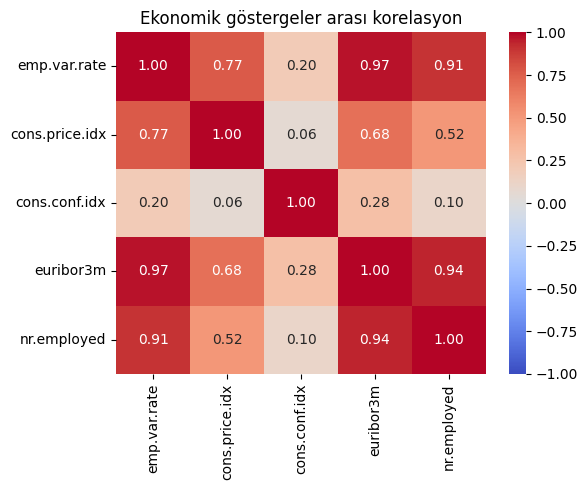

,Farklı değer sayısı
emp.var.rate,10
cons.price.idx,26
cons.conf.idx,26
euribor3m,316
nr.employed,11


cons.price.idx + nr.employed bilindiğinde cons.conf.idx'in belirsiz kaldığı grup sayısı: 0


In [8]:
# ayrışmanın nedeni -> ekonomik göstergeler aynı bilgiyi taşıyor
ekonomik = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

plt.figure(figsize=(6, 5))
sns.heatmap(X_train[ekonomik].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ekonomik göstergeler arası korelasyon")
plt.tight_layout(); plt.savefig("figures/d5c_ekonomik_korelasyon.png", dpi=300, bbox_inches="tight"); plt.show()

display(df[ekonomik].nunique().rename("Farklı değer sayısı").to_frame())

belirsiz = (df.groupby(["cons.price.idx", "nr.employed"])["cons.conf.idx"].nunique() > 1).sum()
print("cons.price.idx + nr.employed bilindiğinde cons.conf.idx'in belirsiz kaldığı grup sayısı:", belirsiz)

**Yorum:**
Bu hücrede MI ve permutation importance arasındaki ayrışmanın nedeni ekonomik göstergeler üzerinden incelenmiştir.

**1. Korelasyon analizi:** `emp.var.rate`, `euribor3m` ve `nr.employed` arasındaki korelasyonlar 0.91–0.97 aralığındadır. Bu üç gösterge neredeyse aynı bilgiyi taşımaktadır. `cons.price.idx` bu göstergelerle orta düzeyde (0.52–0.77) ilişkilidir. `cons.conf.idx` ise diğer göstergelerle çok düşük korelasyonludur (0.06–0.28). Yalnızca korelasyona bakılsaydı `cons.conf.idx`'in diğerlerinden bağımsız ve yeni bilgi taşıyan bir özellik olduğu düşünülebilirdi.

**2. Farklı değer sayıları:** 41.176 kayıt olmasına rağmen `emp.var.rate` yalnızca 10, `nr.employed` 11, `cons.price.idx` ve `cons.conf.idx` 26'şar farklı değer almaktadır. Bunun nedeni, bu göstergelerin müşteriye değil, aylık olarak açıklanan ülke ekonomisi verilerine ait olmasıdır. Aynı dönemde aranan tüm müşteriler aynı değerleri alır. Dolayısıyla bu sütunlar ortak olarak "aramanın yapıldığı dönem" bilgisini taşır. `euribor3m` ise günlük değişen bir faiz oranı olduğu için 316 farklı değer alır ve daha ayrıntılı bilgi içerir.

**3. Belirlenebilirlik testi:** `cons.price.idx` ve `nr.employed` bilindiğinde `cons.conf.idx`'in birden fazla değer aldığı hiçbir grup yoktur (sonuç: 0). Yani `cons.conf.idx`, diğer iki göstergeden tamamen belirlenebilmektedir ve bu göstergeler bilindiğinde modele yeni bilgi katmamaktadır.

**Sonuç:** Ekonomik göstergeler aynı dönem bilgisinin farklı biçimleridir. MI her özelliğe tek başına baktığı için dönem bilgisini taşıyan tüm göstergelere yüksek puan vermiştir. Permutation importance'ta ise bir gösterge karıştırıldığında model dönem bilgisini diğer göstergelerden almaya devam ettiği için `cons.conf.idx` ve `cons.price.idx` sıfıra yakın önem almıştır. Daha ayrıntılı bilgi taşıyan `euribor3m` ve `nr.employed` ise önemini korumuştur.

Bu analiz önemli bir noktayı da göstermektedir: korelasyonun düşük olması iki özelliğin farklı bilgi taşıdığı anlamına gelmez. Korelasyon yalnızca iki özellik arasındaki doğrusal ilişkiyi ölçer. `cons.conf.idx` diğer göstergelerle doğrusal ilişki göstermese de, onların birlikte kullanımıyla tamamen belirlenebilmektedir.

,Özellik sayısı,CV ROC-AUC,Oynama (std)
0,5,0.7799,0.0112
1,10,0.7871,0.0121
2,15,0.7889,0.0112
3,21,0.7888,0.0106


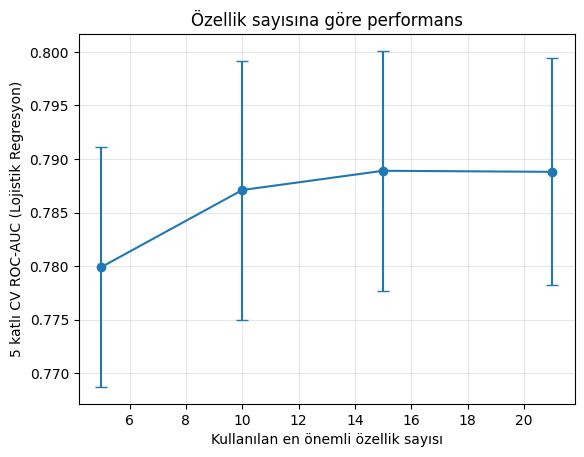

In [9]:
# kaç özellik yeterli?
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

def secili_on_isleyici(secilen):
    """Ortak ön işleyiciyi sadece seçilen sütunlarla kurar."""
    p = on_isleyici()
    p.transformers = [(a, t, [c for c in cols if c in secilen]) for a, t, cols in p.transformers]
    p.transformers = [x for x in p.transformers if x[2]]
    return p

sira = list(pi_ozellik.index)   # permutation importance sırası
sonuc = []
for k in [5, 10, 15, len(sira)]:
    p = Pipeline([("on_isleme", secili_on_isleyici(sira[:k])),
                  ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    s = cross_val_score(p, X_train, y_train, cv=ortak_cv(), scoring="roc_auc", n_jobs=-1)
    sonuc.append({"Özellik sayısı": k, "CV ROC-AUC": round(s.mean(), 4), "Oynama (std)": round(s.std(), 4)})
sonuc = pd.DataFrame(sonuc); display(sonuc)

plt.errorbar(sonuc["Özellik sayısı"], sonuc["CV ROC-AUC"], yerr=sonuc["Oynama (std)"], marker="o", capsize=4)
plt.xlabel("Kullanılan en önemli özellik sayısı"); plt.ylabel("5 katlı CV ROC-AUC (Lojistik Regresyon)")
plt.title("Özellik sayısına göre performans"); plt.grid(alpha=.3)
plt.savefig("figures/d5c_ozellik_sayisi_performans.png", dpi=300, bbox_inches="tight"); plt.show()

**Yorum:**
Permutation importance sıralamasına göre en önemli 5, 10, 15 ve 21 (tüm) özellik seçilerek Lojistik Regresyon modelleri kurulmuş ve 5 katlı çapraz doğrulama ile ROC-AUC skorları ölçülmüştür. Dikey çizgiler, 5 kat arasındaki skor dalgalanmasını (standart sapma) göstermektedir.

- **5 özellik** (`contact`, `euribor3m`, `nr.employed`, `month`, `emp.var.rate`) ile 0.780 ROC-AUC elde edilmiştir. Bu, tüm özelliklerle elde edilen skorun yaklaşık %99'udur. Yani model performansının büyük kısmı aramanın kanalından, ayından ve ekonomik dönemden gelmektedir.
- **10 özelliğe** çıkıldığında skor 0.787'ye yükselmiştir. Eklenen özelliklerin başında önceki kampanya bilgileri (`pdays_kayitli`, `poutcome`, `daha_once_aranmis`) gelmektedir. Bu bilgilerin modele ekonomik dönemden bağımsız bir katkı sağladığı görülmektedir.
- **10 özellikten sonra eğri düzleşmektedir.** 15 özellik (0.7889) ile 21 özellik (0.7888) arasında fark yoktur. Son eklenen 6 özellik (çoğunlukla müşterinin kişisel bilgileri ve tekrarlayan ekonomik göstergeler) modele katkı sağlamamaktadır.
- Noktalar arasındaki farklar, katlar arası dalgalanmadan (yaklaşık ±0.011) küçüktür. Bu nedenle 10, 15 ve 21 özellik arasındaki farklar pratikte önemsizdir.

**Karar:** Az sayıda özellik ile tüm özelliklere yakın performans elde edilebilmektedir. Buna rağmen ortak pipeline'da tüm özellikler tutulmuştur, çünkü:
1. Özellik sayısını azaltmak performansı artırmamaktadır.
2. Veri seti büyük (41.176 kayıt), özellik sayısı ise azdır (21). Fazla özellik bu ölçekte hesaplama veya aşırı öğrenme (overfitting) sorunu yaratmamaktadır.
3. Kullanılan modeller önemsiz özellikleri kendileri etkisizleştirebilmektedir. Ağaç tabanlı modeller bu özelliklerle bölme yapmaz, düzenlileştirme kullanan Lojistik Regresyon ise katsayılarını küçültür.
4. Tüm modeller aynı ortak pipeline ile eğitildiğinden, karşılaştırılabilirliğin korunması amaçlanmıştır.

Bu analizin asıl katkısı, vadeli mevduat kararını belirleyen faktörlerin ortaya konmasıdır: **aramanın yapıldığı ekonomik dönem, arama kanalı ve ayı, müşterinin önceki kampanya geçmişi.** Müşterinin yaş, meslek, eğitim ve kredi durumu gibi kişisel bilgileri ise belirleyici değildir. Bu bulgular, 11 numaralı notebook'taki SHAP analizinin sonuçlarıyla karşılaştırılabilir.